# Run × train comparison (one frame per train)

Compares the bubble populations of **every run and every train** at one frame number (`FRAME_IDX`, default 10),
from the results folders written by `bubble_inference.ipynb` (`results/<run>/`).

**Physical picture:** each femtosecond-laser scan leaves cavitation/vapour bubbles in the tissue. Between trains
(minutes apart) they **coalesce, grow, dissolve and drift**, which changes their number, size, shape and density.
Some trains are recorded while a **new scan layer** is written, which injects a fresh population and makes the
statistics jump. The sections separate these effects and compare runs with each other.

| section | question |
|---|---|
| 2 metrics | every number per run and train in one table (`metrics.csv`) |
| 3 overview | run × train grids of count, size, coverage, … |
| 4 trajectories | each metric over the trains, one line per run, absolute and relative to the first train |
| 5 steps between trains | coalescence, dissolution or new bubbles? which trains jump (new layer candidates)? |
| 6 trends | is there a consistent trend with time, per run and pooled over runs? |
| 7 run vs train | how much of the variation is due to the run, and how much to the train |
| 8 size distributions | distributions per run and train, tests, distances between all frames |
| 9 self-similarity | do the scaled distributions collapse (pure coarsening)? coarsening exponent |
| 9b pooled distribution | all frames in one histogram, with the spread between runs; asymmetric fits (lognormal, gamma, Weibull, generalised gamma, two lognormals) |
| 10 spatial | clustering (nearest neighbours) and drift of the population |
| 11 shape | elongated bubbles as a marker of recent mergers |
| 12 layer trains | how layer / outlier trains differ from the rest |
| 13 overlays | the frames themselves, coloured by bubble area |
| **14 findings** | **text box with all significant findings, to paste back to Claude** |

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%load_ext autoreload
%autoreload 2
import bubble_io as bio
import bubble_stats as bst
import bubble_compare as bc

bst.style()
F = bc.Findings()      # every section adds its findings here; printed in section 14

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## CONFIG

In [13]:
RESULTS_ROOT = "results"
RUNS = ["r562_set"]                   # None = every run folder in RESULTS_ROOT; or e.g. ["r563", "r571"]
FRAME_IDX = 10                 # frame number used in every train
REVIEWED_ONLY = False          # True: only frames ticked "Reviewed" in napari; False: model predictions too
IN_ANALYSIS_ONLY = True        # apply the exclusions chosen at export (inner_margin, drop_edge_bubbles, ...)
EXPORT_MISSING = True          # write bubbles.csv from the shape files where it is missing or empty
MIN_BUBBLES = 30               # drop frames with fewer bubbles (trains before the scan reached the field of view)
TRAIN_TIMES = None             # None = train number; {train: minutes} for all runs; or {run: {train: minutes}}
TIME_LABEL = "train"           # e.g. "time since scan [min]" when TRAIN_TIMES is set
KNOWN_LAYER_TRAINS = {}        # trains recorded during a new scan layer, e.g. {"r563": [4], "r571": [3, 6]}
UM_PER_PX = 3.2
SMALL_UM = 10.0                # "small bubble" radius limit (fresh population indicator)
OUTLIER_Z = 3.0                # robust z-score above which a step between trains counts as a jump
ALPHA = 0.05                   # significance level for the findings box
EXCLUDE_LAYERS_FROM_TRENDS = True
FIT_RMIN_UM = 5.0              # pooled fits: radii below this are treated as undetected (left truncation)
FIT_TAIL_RMIN_UM = 10.0        # second fit above the small-bubble peak, to check the tail on its own
FIT_WEIGHT = "frame"           # "frame": every frame counts the same; "bubble": busy frames dominate; or "run"
FIT_EXCLUDE_LAYERS = False     # True: leave layer / jump trains out of the pooled fit
N_BOOT = 100                   # resamples of whole runs for the uncertainty of the lognormal fit (0 = skip)
SHOW_OVERLAYS = True           # section 13 (needs the frame .tif copies in each run's shapes/ folder)

OUT_DIR = os.path.join(RESULTS_ROOT, "_compare", f"frame{FRAME_IDX:03d}")
SAVE_FIGS = True

def save(fig, name):
    if SAVE_FIGS:
        os.makedirs(os.path.join(OUT_DIR, "figures"), exist_ok=True)
        fig.savefig(os.path.join(OUT_DIR, "figures", name + ".png"), dpi=200, bbox_inches="tight")

## 1. Load

One row per bubble (`bubbles`) and per frame (`frames`) from every run, each with `run`, `train` and `t`. Runs are
named from the frame names (`r563_svd_…` → `r563`), so one folder per run or several runs in one folder both work.

In [14]:
run_dirs = bc.find_run_dirs(RESULTS_ROOT, RUNS)
print("run folders:", run_dirs)
bubbles, frames = bc.load_runs(run_dirs, frame_idx=FRAME_IDX, reviewed_only=REVIEWED_ONLY,
                               in_analysis_only=IN_ANALYSIS_ONLY, train_times=TRAIN_TIMES,
                               export_missing=EXPORT_MISSING)
bubbles, frames, DROPPED = bc.drop_sparse(bubbles, frames, MIN_BUBBLES)
if DROPPED:
    print(f"dropped {len(DROPPED)} frames with < {MIN_BUBBLES} bubbles (run, train, n):", DROPPED)
RUNS_FOUND = sorted(frames["run"].unique())
NATIVE_HW = (int(frames["image_height_px"].iloc[0]), int(frames["image_width_px"].iloc[0]))
COLS = bc.run_colors(RUNS_FOUND)
display(frames.pivot_table(index="run", columns="train", values="n_bubbles", aggfunc="sum").fillna(0).astype(int))
n_rev = int(frames["reviewed"].sum())
F.add("Data", f"{len(RUNS_FOUND)} runs ({', '.join(RUNS_FOUND)}), frame {FRAME_IDX} of trains "
      f"{sorted(frames['train'].unique().tolist())}: {len(frames)} frames, {len(bubbles)} bubbles; "
      f"{n_rev}/{len(frames)} frames reviewed in napari (the rest are raw model predictions). "
      f"Field of view {NATIVE_HW[1] * UM_PER_PX:.0f} × {NATIVE_HW[0] * UM_PER_PX:.0f} µm, time axis: {TIME_LABEL}.")
if DROPPED:
    F.add("Data", f"left out {len(DROPPED)} frames with < {MIN_BUBBLES} bubbles (before the scan reached the field of "
          f"view?), (run, train, n): {DROPPED}")
missing = [(r, int(t)) for r in RUNS_FOUND for t in sorted(frames["train"].unique())
           if not ((frames["run"] == r) & (frames["train"] == t)).any()]
if missing:
    F.add("Data", f"missing frames (run, train): {missing}")

run folders: ['results/r562_set']
3 runs, 24 frames, 6427 bubbles


,trains,n_frames,bubbles
run,,,
r562,"0,1,2,3,4,5,6,7,8",9,1727
r563,"0,1,2,3,4,5,6,7",8,2649
r564,"0,1,2,3,4,5,6",7,2051


dropped 5 frames with < 30 bubbles (run, train, n): [('r562', 0, 16), ('r562', 1, 16), ('r562', 2, 12), ('r562', 3, 11), ('r562', 4, 26)]


train,0,1,2,3,4,5,6,7,8
run,,,,,,,,,
r562,0,0,0,0,0,448,438,390,370
r563,319,302,279,256,431,387,345,330,0
r564,265,242,231,395,349,302,267,0,0


## 2. Metrics per run and train

Everything from `bubble_analysis.ipynb` (`n_bubbles`, `density_per_mm2`, mean / median / Sauter radius `r32_um`,
`polydispersity` = std/mean, `coverage_frac`, `volume_um3` = Σ 4/3πr³, `frac_noncircular`, centroid `cx_um, cy_um`),
plus: `frac_small` (share with r < `SMALL_UM`), `r_p90_um`, `log_width` (std of ln r, scale-free width),
`nn_mean_um` (mean nearest-neighbour distance), `clark_evans` (1 = random, < 1 clustered, > 1 evenly spaced) and
`packing` (total bubble area / frame area; above `coverage_frac` when bubbles overlap).

In [15]:
m = bc.metrics(bubbles, frames, um_per_px=UM_PER_PX, small_um=SMALL_UM)
os.makedirs(OUT_DIR, exist_ok=True)
m.to_csv(os.path.join(OUT_DIR, "metrics.csv"), index=False)
show = ["run", "train", "t", "n_bubbles", "density_per_mm2", "r_mean_um", "r_median_um", "r32_um", "polydispersity",
        "coverage_frac", "volume_um3", "frac_small", "frac_noncircular", "nn_mean_um", "clark_evans"]
display(m[[c for c in show if c in m]].round(3))

LABELS = {"n_bubbles": "bubble count", "density_per_mm2": "density [1/mm²]", "r_mean_um": "mean radius [µm]",
          "r_median_um": "median radius [µm]", "r32_um": "Sauter radius r₃₂ [µm]", "r_p90_um": "90th pct radius [µm]",
          "polydispersity": "polydispersity", "log_width": "width of ln r", "coverage_frac": "coverage",
          "packing": "packing (Σ area / frame)", "volume_um3": "gas volume proxy [µm³]", "frac_small": f"share r < {SMALL_UM:g} µm",
          "frac_noncircular": "share non-circular", "nn_mean_um": "nearest-neighbour dist. [µm]",
          "clark_evans": "Clark-Evans R", "aspect_median": "median aspect ratio"}
KEY = [c for c in ["n_bubbles", "r_mean_um", "r_median_um", "r32_um", "polydispersity", "coverage_frac", "volume_um3",
                   "frac_small", "frac_noncircular", "nn_mean_um", "clark_evans"] if c in m]
# layer trains: known ones plus the fresh-population jumps detected in section 5 (computed here so every figure marks them)
st = bc.outlier_steps(bc.steps(m), z_thresh=OUTLIER_Z)
LAYERS = bc.layer_set(st, KNOWN_LAYER_TRAINS)
print("layer trains (known + detected):", sorted(LAYERS))
LOG_COLS = {"n_bubbles", "density_per_mm2", "r_mean_um", "r_median_um", "r32_um", "r_p90_um", "volume_um3",
            "area_total_um2", "nn_mean_um"}

,run,train,t,n_bubbles,density_per_mm2,r_mean_um,r_median_um,r32_um,polydispersity,coverage_frac,volume_um3,frac_small,frac_noncircular,nn_mean_um,clark_evans
0,r562,5,5.0,448,437.500,16.801,13.362,36.922,0.701,0.372,2.913518e+07,0.326,0.054,21.806,0.890
1,r562,6,6.0,438,427.734,17.233,13.516,36.324,0.674,0.375,2.877194e+07,0.279,0.055,21.651,0.872
2,r562,7,7.0,390,380.859,18.122,14.113,37.459,0.670,0.362,2.909716e+07,0.251,0.054,22.553,0.853
3,r562,8,8.0,370,361.328,18.421,15.099,37.577,0.658,0.351,2.828329e+07,0.219,0.051,23.196,0.854
4,r563,0,0.0,319,311.523,19.597,16.293,38.144,0.636,0.334,2.746723e+07,0.201,0.041,23.648,0.803
5,r563,1,1.0,302,294.922,19.723,16.678,38.115,0.635,0.323,2.628344e+07,0.195,0.050,24.619,0.812
6,r563,2,2.0,279,272.461,20.090,17.149,38.531,0.627,0.317,2.530451e+07,0.176,0.047,25.444,0.809
7,r563,3,3.0,256,250.000,20.964,17.596,39.591,0.624,0.311,2.589740e+07,0.176,0.066,26.692,0.813
8,r563,4,4.0,431,420.898,16.387,12.552,38.141,0.731,0.339,2.835676e+07,0.348,0.049,22.306,0.888
9,r563,5,5.0,387,377.930,16.882,13.584,38.200,0.713,0.329,2.660636e+07,0.326,0.049,23.250,0.875


layer trains (known + detected): [('r563', 4), ('r564', 3)]


## 3. Overview: run × train grids

Each panel has its own colour scale (darker = higher). Black boxes: layer trains (known, or detected as jumps in
section 5).

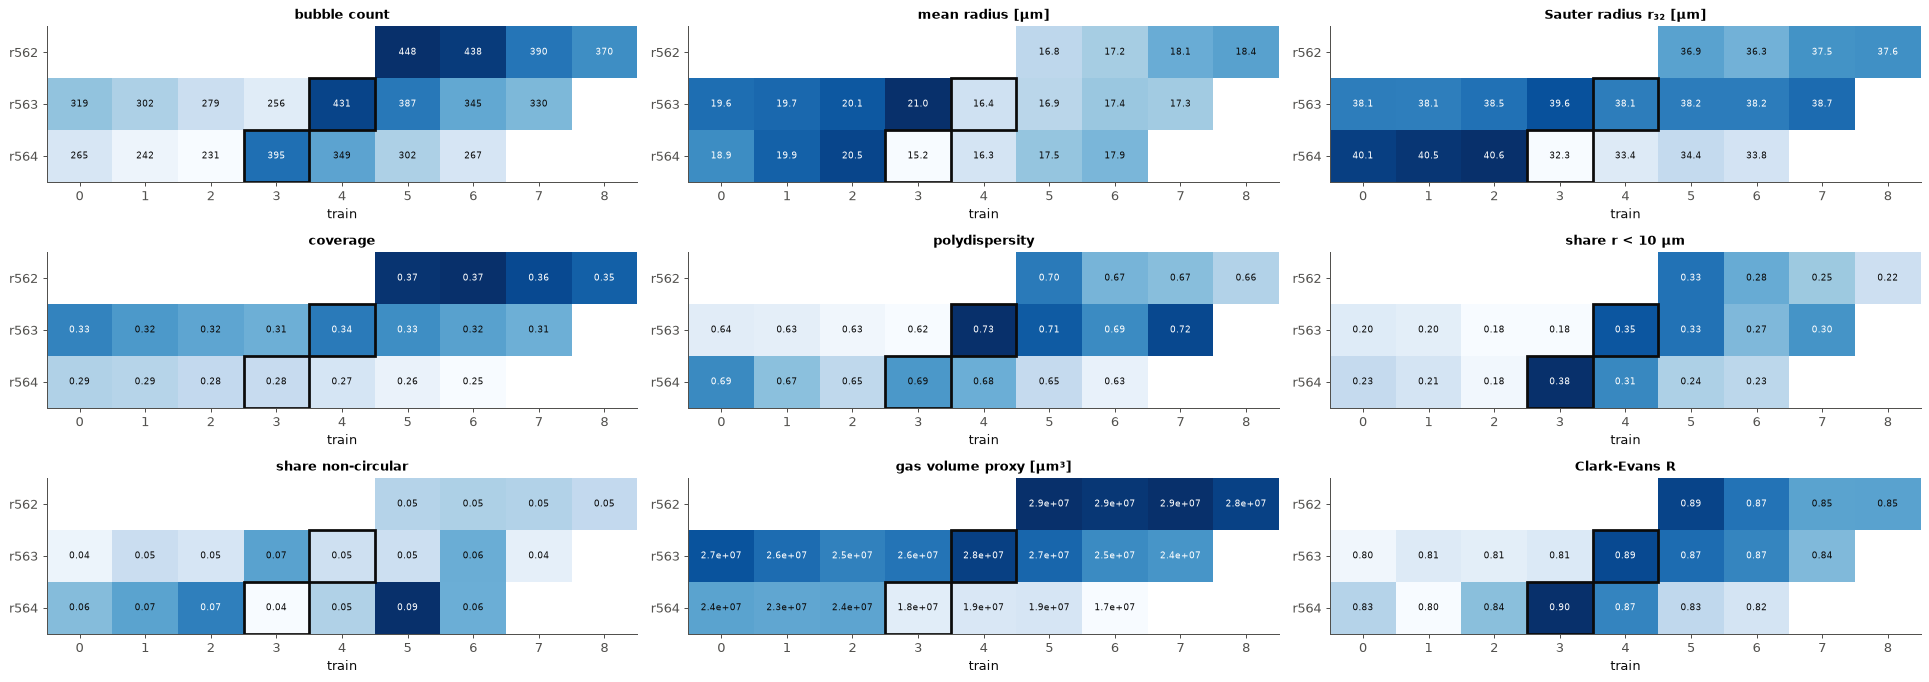

In [16]:
SPECS = [("n_bubbles", "bubble count", ".0f"), ("r_mean_um", "mean radius [µm]", ".1f"),
         ("r32_um", "Sauter radius r₃₂ [µm]", ".1f"), ("coverage_frac", "coverage", ".2f"),
         ("polydispersity", "polydispersity", ".2f"), ("frac_small", f"share r < {SMALL_UM:g} µm", ".2f"),
         ("frac_noncircular", "share non-circular", ".2f"), ("volume_um3", "gas volume proxy [µm³]", ".2g"),
         ("clark_evans", "Clark-Evans R", ".2f")]
SPECS = [s for s in SPECS if s[0] in m]
fig = bc.plot_heatmaps(m, SPECS, layers=LAYERS)
save(fig, "overview_grids")

F.clear("Runs compared (mean over trains)")
for col in ["n_bubbles", "r_mean_um", "r32_um", "coverage_frac", "polydispersity", "frac_small"]:
    if col not in m:
        continue
    g = m.groupby("run")[col].mean().sort_values()
    if len(g) > 1:
        F.add("Runs compared (mean over trains)",
              f"{LABELS[col]}: lowest {g.index[0]} ({g.iloc[0]:.3g}), highest {g.index[-1]} ({g.iloc[-1]:.3g}), "
              f"ratio {g.iloc[-1] / g.iloc[0]:.2f}; all runs: " + ", ".join(f"{r} {v:.3g}" for r, v in g.items()))

## 4. Trajectories over the trains

Top: absolute values. Bottom: relative to each run's first train, which removes offsets between runs (different
starting conditions) and shows whether runs **evolve** the same way.

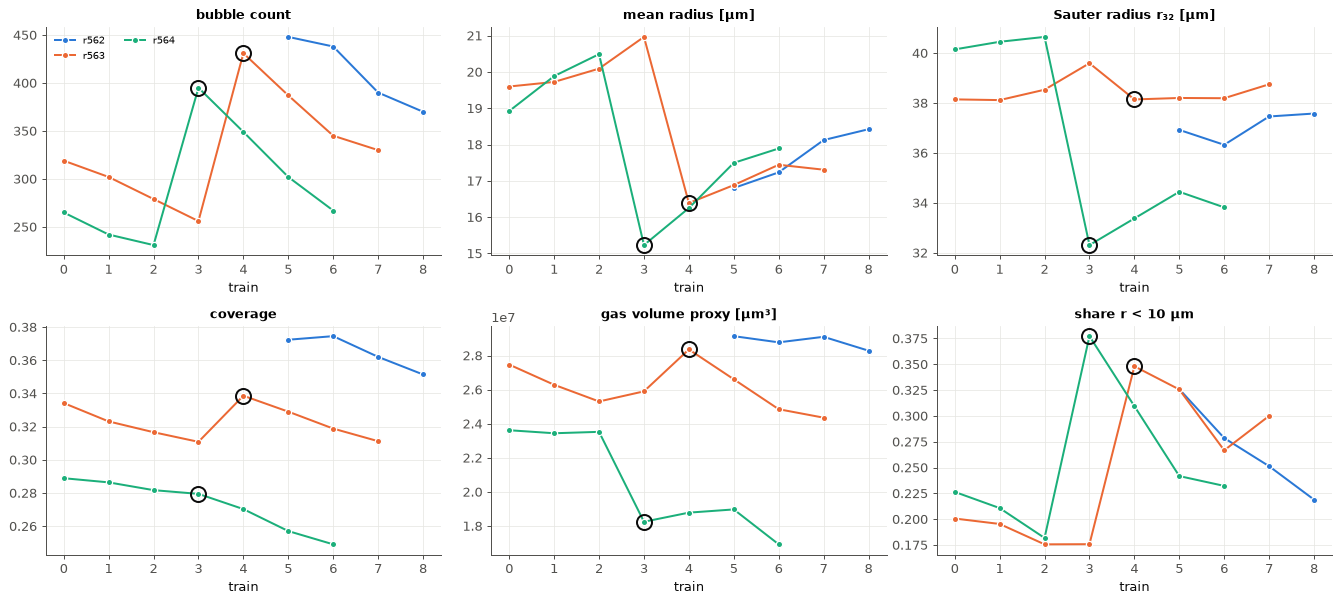

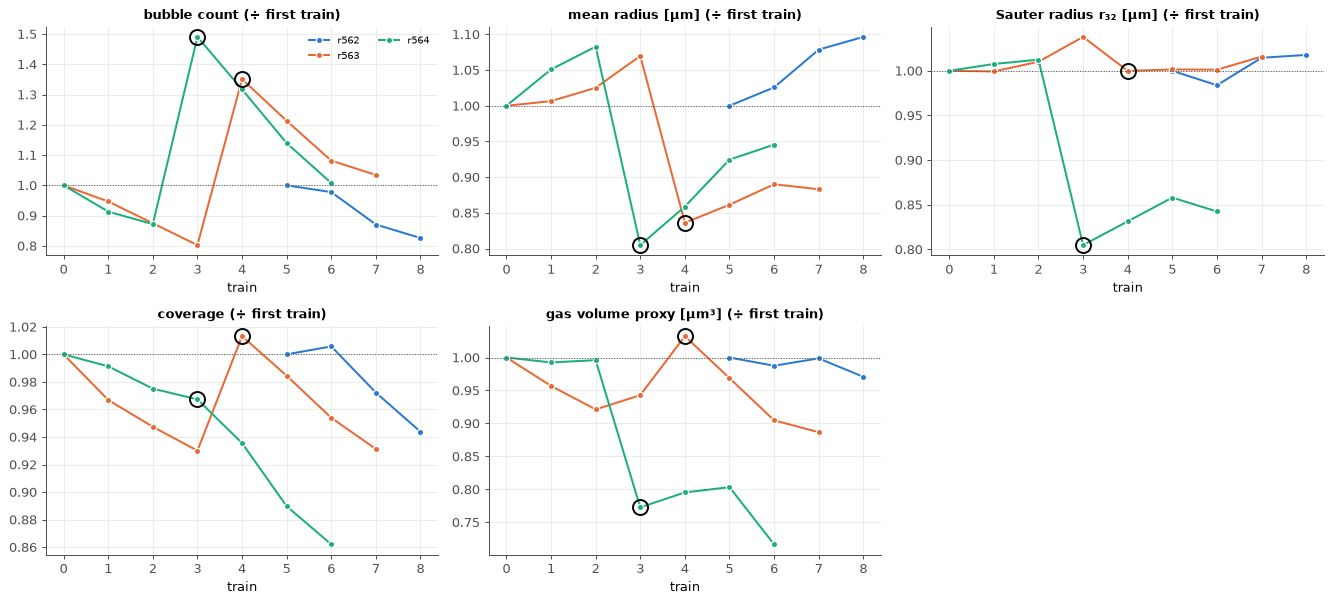

In [17]:
TSPECS = [s for s in [("n_bubbles", "bubble count", ""), ("r_mean_um", "mean radius [µm]", ""),
                      ("r32_um", "Sauter radius r₃₂ [µm]", ""), ("coverage_frac", "coverage", ""),
                      ("volume_um3", "gas volume proxy [µm³]", ""), ("frac_small", f"share r < {SMALL_UM:g} µm", "")]
          if s[0] in m]
fig = bc.plot_trajectories(m, TSPECS, TIME_LABEL, layers=LAYERS)
save(fig, "trajectories")
fig = bc.plot_trajectories(m, TSPECS[:5], TIME_LABEL, layers=LAYERS, relative=True)
save(fig, "trajectories_relative")

F.clear("Net change first → last train")
for run, g in m.sort_values("t").groupby("run"):
    a, b = g.iloc[0], g.iloc[-1]
    F.add("Net change first → last train",
          f"{run} (train {a.train} → {b.train}): count {a.n_bubbles:.0f} → {b.n_bubbles:.0f} "
          f"(×{b.n_bubbles / max(a.n_bubbles, 1):.2f}), mean r {a.r_mean_um:.1f} → {b.r_mean_um:.1f} µm "
          f"(×{b.r_mean_um / a.r_mean_um:.2f}), r32 ×{b.r32_um / a.r32_um:.2f}, gas volume ×{b.volume_um3 / a.volume_um3:.2f}"
          + (f", coverage {a.coverage_frac:.2f} → {b.coverage_frac:.2f}" if "coverage_frac" in m else ""))

## 5. Steps between consecutive trains

Each step is classified by what dominated (`bubble_compare.steps`):

| class | signature |
|---|---|
| **coalescence** | count down, mean radius up, gas volume roughly conserved |
| **growth** | gas volume up (count not up) |
| **dissolution** | gas volume down (count not up) |
| **new bubbles** | count up and mean radius down (fresh population, e.g. a new scan layer) |

Steps whose change in count, median radius or small-bubble share is far outside the typical step (robust
z > `OUTLIER_Z` over all runs) are flagged as **jumps**. A jump to more and smaller bubbles (`fresh`) makes the train
after it a candidate layer train; the jump straight back afterwards is the layer ending. Add the layer trains you
know to `KNOWN_LAYER_TRAINS` and rerun from section 3.

,run,train_from,train_to,count_ratio,r_mean_ratio,volume_ratio,frac_small_change,kind,z,flagged,fresh,what,D,p
0,r562,5,6,0.978,1.026,0.988,-0.047,little change,1.165,False,False,,0.059,0.403
1,r562,6,7,0.890,1.052,1.011,-0.027,coalescence,0.649,False,False,,0.056,0.513
2,r562,7,8,0.949,1.017,0.972,-0.032,little change,0.986,False,False,,0.055,0.581
3,r563,0,1,0.947,1.006,0.957,-0.005,little change,0.576,False,False,,0.031,0.996
4,r563,1,2,0.924,1.019,0.963,-0.020,little change,0.066,False,False,,0.043,0.937
5,r563,2,3,0.918,1.043,1.023,0.000,little change,0.773,False,False,,0.053,0.827
6,r563,3,4,1.684,0.782,1.095,0.172,new bubbles,11.706,True,True,"count ×1.68, median r ×0.71, small share +17 p...",0.259,0.000
7,r563,4,5,0.898,1.030,0.938,-0.022,coalescence,1.281,False,False,,0.078,0.159
8,r563,5,6,0.891,1.033,0.934,-0.059,coalescence,1.376,False,False,,0.069,0.326
9,r563,6,7,0.957,0.992,0.980,0.033,little change,1.980,False,False,,0.058,0.598


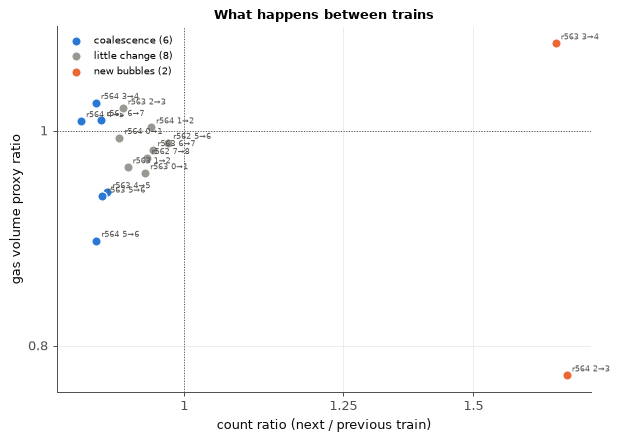

In [18]:
ks = bc.consecutive_ks(bubbles, m)
st = st.merge(ks, on=["run", "train_from", "train_to"], how="left")
st.to_csv(os.path.join(OUT_DIR, "steps.csv"), index=False)
display(st[["run", "train_from", "train_to", "count_ratio", "r_mean_ratio", "volume_ratio", "frac_small_change",
            "kind", "z", "flagged", "fresh", "what", "D", "p"]].round(3))
fig = bc.plot_steps(st)
save(fig, "steps")

F.clear("Steps between trains")
kinds = st["kind"].value_counts()
F.add("Steps between trains", f"{len(st)} steps: " + ", ".join(f"{k} {v}" for k, v in kinds.items()) + ".")
for run, g in st.groupby("run"):
    F.add("Steps between trains", f"{run}: " + "; ".join(f"{r.train_from}→{r.train_to} {r.kind} "
          f"(N×{r.count_ratio:.2f}, r×{r.r_mean_ratio:.2f}, V×{r.volume_ratio:.2f})" for r in g.itertuples()))
for r in st[st["flagged"]].itertuples():
    F.add("Steps between trains", f"JUMP {r.run} train {r.train_from}→{r.train_to} (z = {r.z:.1f}): {r.what}")
if not st["flagged"].any():
    F.add("Steps between trains", f"no step stands out (all robust z ≤ {OUTLIER_Z:g})")
if KNOWN_LAYER_TRAINS:
    det = {(r.run, r.train_to) for r in st[st["fresh"]].itertuples()}
    known = {(r, t) for r, ts in KNOWN_LAYER_TRAINS.items() for t in ts}
    F.add("Steps between trains", f"known layer trains detected as jumps: {sorted(known & det)}; "
          f"known but not detected: {sorted(known - det)}; detected but not listed as known: {sorted(det - known)}")
sig_ks = st[st["p"] < ALPHA]
F.add("Steps between trains", f"size distribution changes significantly (KS, p < {ALPHA}) in {len(sig_ks)}/{len(st)} "
      f"steps; largest KS D = {st['D'].max():.2f} ({st.loc[st['D'].idxmax(), 'run']} "
      f"{st.loc[st['D'].idxmax(), 'train_from']}→{st.loc[st['D'].idxmax(), 'train_to']})")

## 6. Trends with time

Per run: Spearman ρ (monotonic trend) and a linear fit (on ln y for counts and sizes, reported as % per unit of
`TIME_LABEL`). **Pooled**: one common slope for all runs after removing each run's own level, i.e. "do runs share
a trend?". Layer trains are left out when `EXCLUDE_LAYERS_FROM_TRENDS = True`, so a sudden fresh population does
not masquerade as a trend.

In [19]:
TREND_COLS = [c for c in ["n_bubbles", "r_mean_um", "r_median_um", "r32_um", "polydispersity", "coverage_frac",
                          "volume_um3", "frac_small", "frac_noncircular", "nn_mean_um", "clark_evans"] if c in m]
tr = bc.trends(m, TREND_COLS, exclude=LAYERS if EXCLUDE_LAYERS_FROM_TRENDS else None, log_cols=LOG_COLS)
tr.to_csv(os.path.join(OUT_DIR, "trends.csv"), index=False)
display(tr.pivot_table(index="metric", columns="run", values="spearman_rho").round(2))
display(tr[tr["run"] == "all (pooled)"].set_index("metric")[["n", "spearman_rho", "spearman_p", "slope", "slope_p", "pct_per_t"]].round(4))

F.clear("Trends with time")
note = " (layer trains excluded)" if EXCLUDE_LAYERS_FROM_TRENDS and LAYERS else ""
for r in tr[tr["run"] == "all (pooled)"].itertuples():
    if r.slope_p < ALPHA:
        per = f"{r.pct_per_t:+.1f}% per {TIME_LABEL}" if np.isfinite(r.pct_per_t) else f"{r.slope:+.3g} per {TIME_LABEL}"
        sub = tr[(tr["metric"] == r.metric) & (tr["run"] != "all (pooled)")]
        agree = int((np.sign(sub["slope"]) == np.sign(r.slope)).sum())
        F.add("Trends with time", f"{LABELS.get(r.metric, r.metric)}: pooled {per}, {bc.fmt_p(r.slope_p)}, "
              f"ρ = {r.spearman_rho:+.2f}; same direction in {agree}/{len(sub)} runs{note}")
ns = [LABELS.get(r.metric, r.metric) for r in tr[tr["run"] == "all (pooled)"].itertuples() if not r.slope_p < ALPHA]
if ns:
    F.add("Trends with time", f"no significant pooled trend (p ≥ {ALPHA}): " + ", ".join(ns))
for r in tr[(tr["run"] != "all (pooled)") & (tr["spearman_p"] < ALPHA)].itertuples():
    pooled = tr[(tr["metric"] == r.metric) & (tr["run"] == "all (pooled)")]
    if len(pooled) and (pooled["slope_p"].iloc[0] >= ALPHA or np.sign(pooled["slope"].iloc[0]) != np.sign(r.slope)):
        F.add("Trends with time", f"{r.run} alone: {LABELS.get(r.metric, r.metric)} trend ρ = {r.spearman_rho:+.2f} "
              f"({bc.fmt_p(r.spearman_p)}), unlike the pooled result")

run,all (pooled),r562,r563,r564
metric,,,,
clark_evans,0.51,-0.8,0.82,-0.09
coverage_frac,-0.71,-0.8,-0.50,-1.00
frac_noncircular,0.14,-0.4,0.21,0.20
frac_small,0.47,-1.0,0.57,0.54
n_bubbles,0.38,-1.0,0.50,0.54
nn_mean_um,-0.24,0.8,-0.14,-0.54
polydispersity,0.20,-1.0,0.61,-0.83
r32_um,-0.30,0.8,0.54,-0.60
r_mean_um,-0.57,1.0,-0.54,-0.54


,n,spearman_rho,spearman_p,slope,slope_p,pct_per_t
metric,,,,,,
n_bubbles,17,0.3824,0.1299,0.0211,0.1827,2.1347
r_mean_um,17,-0.5686,0.0172,-0.0208,0.0161,-2.0543
r_median_um,17,-0.5049,0.0387,-0.0236,0.0241,-2.3321
r32_um,17,-0.3015,0.2396,-0.0128,0.0576,-1.2746
polydispersity,17,0.2034,0.4336,0.0044,0.2503,NaN
coverage_frac,17,-0.7132,0.0013,-0.0040,0.0017,NaN
volume_um3,17,-0.7574,0.0004,-0.0291,0.0019,-2.8685
frac_small,17,0.4657,0.0596,0.0109,0.0703,NaN
frac_noncircular,17,0.1422,0.5863,0.0009,0.4270,NaN


## 7. Run vs train: what drives the variation?

For each metric, the variation over all frames is split into the part explained **only by the run** (runs differ
in level), **only by the train** (a shared evolution with time), **shared** (run and train confounded, e.g. missing
trains) and **run × train + noise** (runs evolving differently, plus frame-to-frame scatter; with one frame per
train the two cannot be separated).

,run_only,train_only,shared,interaction_noise
metric,,,,
n_bubbles,0.30,0.34,0.13,0.23
r_mean_um,0.03,0.60,0.02,0.35
r_median_um,0.08,0.59,0.02,0.31
r32_um,0.14,0.38,0.01,0.47
polydispersity,0.00,0.39,0.01,0.60
coverage_frac,0.80,0.06,0.10,0.04
volume_um3,0.74,0.13,0.03,0.10
frac_small,0.01,0.58,0.01,0.41
frac_noncircular,0.22,0.20,0.01,0.57


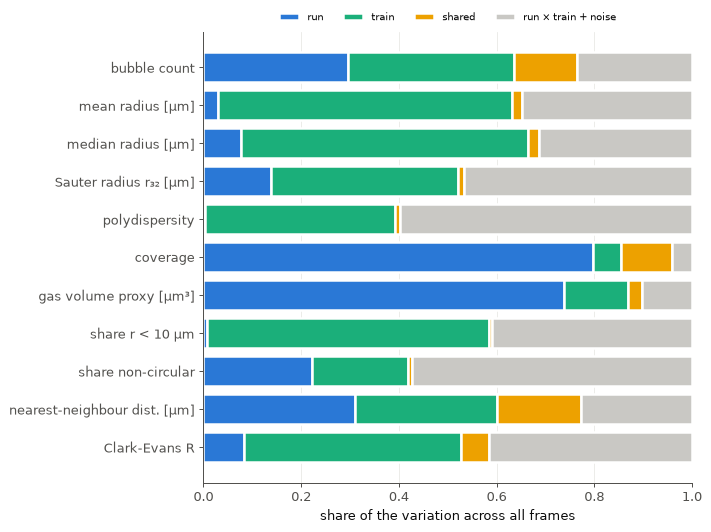

In [20]:
vp = bc.variance_partition(m, TREND_COLS)
display(vp.round(2))
fig = bc.plot_variance_partition(vp, LABELS)
save(fig, "variance_partition")

F.clear("Run vs train")
for metric, r in vp.iterrows():
    dom = max([("run", r.run_only), ("train/time", r.train_only), ("run × train + noise", r.interaction_noise)],
              key=lambda x: x[1])
    F.add("Run vs train", f"{LABELS.get(metric, metric)}: run {r.run_only:.0%}, train {r.train_only:.0%}, "
          f"rest {r.interaction_noise:.0%} → mostly {dom[0]}")

## 8. Size distributions

* **Heatmaps per run:** each column is one train's size distribution (fraction of its bubbles per size bin), the
  orange line the median.
* **Cumulative distributions per train:** the runs compared at the same train.
* **Tests:** Kruskal-Wallis across runs at each train, and across trains within each run. With hundreds of bubbles
  per frame small differences become significant, so the **effect size ε²** matters (0.01 small, 0.06 medium,
  0.14 large).
* **Distances:** Wasserstein distance between the ln r distributions of every pair of frames (0.1 ≈ all radii
  10 % apart). Comparing the average distance within runs with that between runs at the same train tells whether
  runs or time dominate.

,train,k,n,H,p,epsilon2
0,0,2,584,2.1513,0.1425,0.0020
1,1,2,544,0.0821,0.7745,0.0000
2,2,2,510,0.0009,0.9757,0.0000
3,3,2,651,59.3356,0.0000,0.0899
4,4,2,780,0.1841,0.6679,0.0000
5,5,3,1137,3.0286,0.2200,0.0009
6,6,3,1050,1.6422,0.4399,0.0000
7,7,2,720,2.3375,0.1263,0.0019


,run,k,n,H,p,epsilon2
0,r562,4,1646,10.4560,0.0151,0.0045
1,r563,8,2649,90.6750,0.0000,0.0317
2,r564,7,2051,66.0857,0.0000,0.0294


{'same_run_diff_train': 0.124, 'same_train_diff_run': 0.073, 'different_both': 0.118}


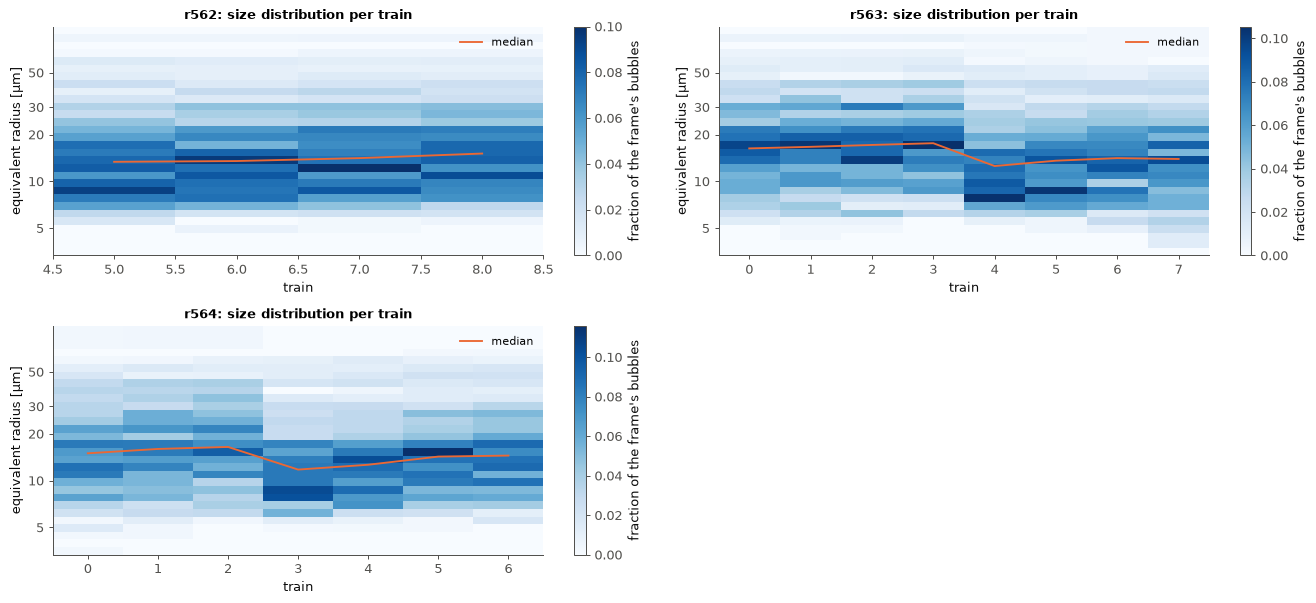

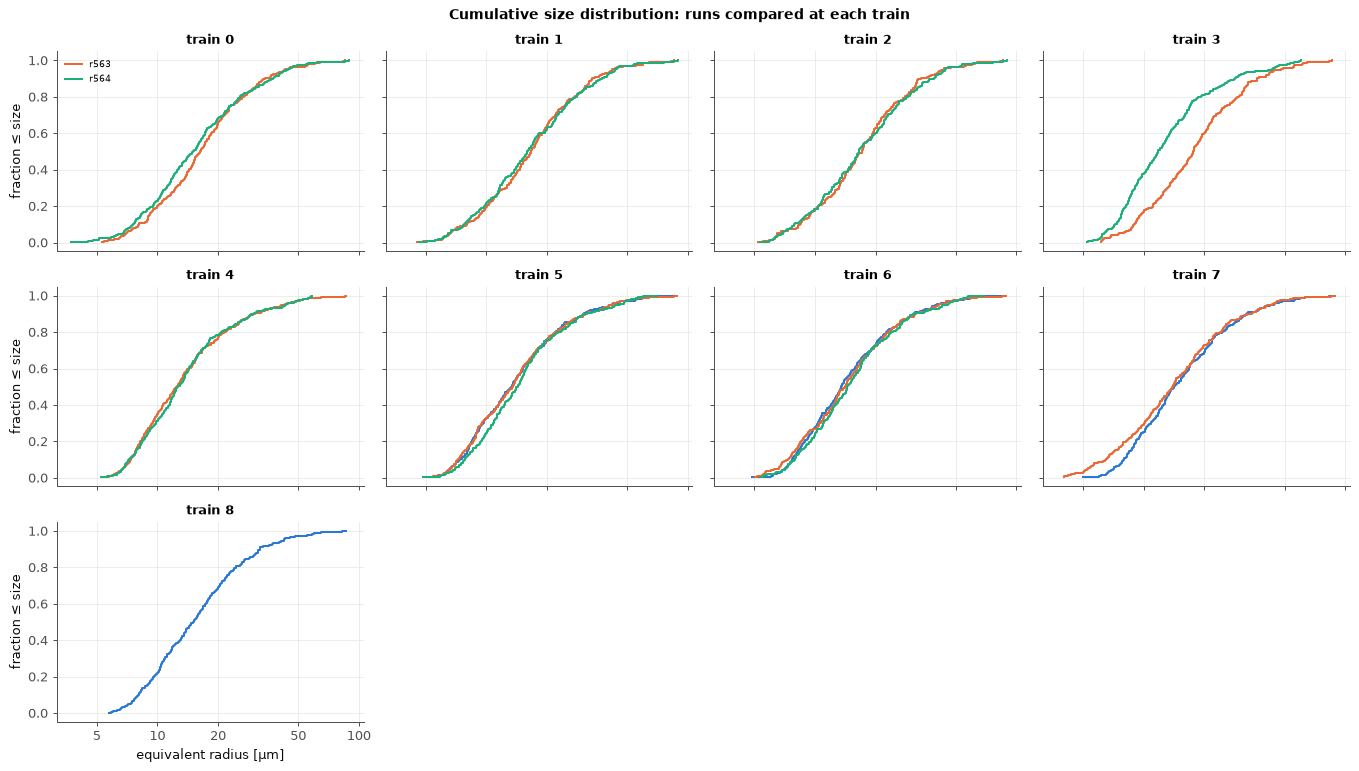

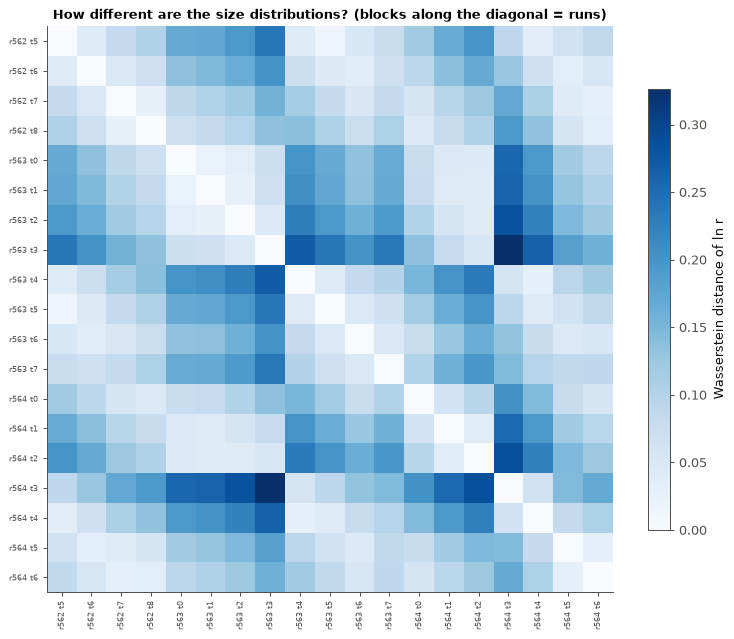

In [21]:
fig = bc.plot_size_heatmaps(bubbles, m, TIME_LABEL)
save(fig, "size_heatmaps")
fig = bc.plot_cdfs_by_train(bubbles, m)
save(fig, "cdfs_by_train")

kw_runs = bc.kruskal_across(bubbles, "run", "train")
kw_trains = bc.kruskal_across(bubbles, "train", "run")
display(kw_runs.round(4)); display(kw_trains.round(4))
D, order = bc.w1_matrix(bubbles, m)
fig = bc.plot_w1(D)
save(fig, "w1_matrix")
ws = bc.w1_summary(D, order)
print({k: round(v, 3) for k, v in ws.items()})

F.clear("Size distributions")
if len(kw_runs):
    sig = kw_runs[kw_runs["p"] < ALPHA]
    F.add("Size distributions", f"runs differ at the same train (Kruskal-Wallis p < {ALPHA}) in {len(sig)}/{len(kw_runs)} "
          f"trains; effect size ε² median {kw_runs['epsilon2'].median():.3f} (max {kw_runs['epsilon2'].max():.3f}, "
          f"train {kw_runs.loc[kw_runs['epsilon2'].idxmax(), 'train']})")
if len(kw_trains):
    F.add("Size distributions", "change across trains within a run, ε²: " +
          ", ".join(f"{r.run} {r.epsilon2:.3f} ({bc.fmt_p(r.p)})" for r in kw_trains.itertuples()))
F.add("Size distributions", f"mean Wasserstein distance of ln r: same run / other trains {ws['same_run_diff_train']:.3f}, "
      f"same train / other runs {ws['same_train_diff_run']:.3f}, both different {ws['different_both']:.3f} → "
      + ("the train (time) changes the distribution more than the run does"
         if ws["same_run_diff_train"] > ws["same_train_diff_run"] else
         "runs differ more from each other than trains within a run"))

## 9. Self-similarity and coarsening

If the foam simply coarsens, the distribution of r/⟨r⟩ keeps its shape while ⟨r⟩ grows, and all curves collapse.
Layer trains (orange) are expected to break the collapse with an excess of small bubbles. With real times in
`TRAIN_TIMES` (time since the scan, t > 0), the Sauter radius is fitted as r₃₂ ∝ t^α (α = 1/3 Ostwald ripening,
≈ 1/2 coalescence-dominated coarsening).

set TRAIN_TIMES (time since the scan) to fit a coarsening exponent


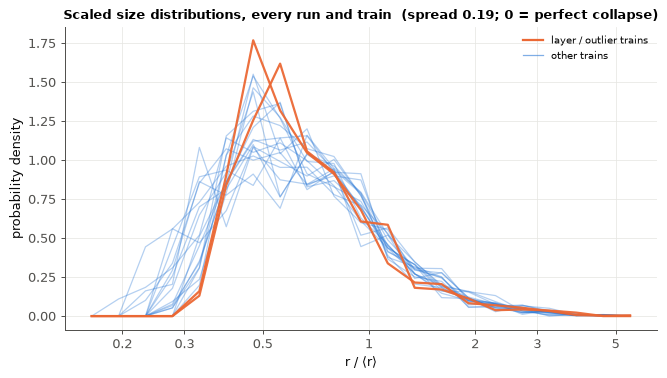

In [22]:
centers, curves, cv = bc.scaled_curves(bubbles, m)
fig = bc.plot_scaled(centers, curves, layers=LAYERS, cv=cv)
save(fig, "scaled_distributions")
F.clear("Self-similarity")
if LAYERS:
    plain = {k: v for k, v in curves.items() if k not in LAYERS}
    _, _, cv_plain = bc.scaled_curves(bubbles, m[[(r, t) not in LAYERS for r, t in zip(m["run"], m["train"])]])
    F.add("Self-similarity", f"scaled-distribution spread {cv:.2f} with all trains, {cv_plain:.2f} without layer "
          f"trains (0 = perfect collapse)")
else:
    F.add("Self-similarity", f"scaled-distribution spread {cv:.2f} (0 = perfect collapse; ~0.2 or less is a good collapse)")
F.add("Self-similarity", "distribution width (std of ln r) per run, first → last train: " + ", ".join(
    f"{run} {g['log_width'].iloc[0]:.2f} → {g['log_width'].iloc[-1]:.2f}" for run, g in m.sort_values("t").groupby("run")))

if TRAIN_TIMES and (m["t"] > 0).any():
    ce = bc.coarsening_exponent(m, "r32_um")
    display(ce.round(3))
    F.add("Self-similarity", "coarsening exponent r32 ∝ t^α: " + ", ".join(
        f"{r.run} α = {r.alpha:.2f} ± {r.alpha_se:.2f} (R² {r.r2:.2f})" for r in ce.itertuples()))
else:
    print("set TRAIN_TIMES (time since the scan) to fit a coarsening exponent")

## 9b. Pooled size distribution and asymmetric fits

All frames (every run and train) in one histogram, so the run-to-run scatter averages out. The band shows how much
single runs scatter around it (16–84 % of runs). The right panel divides each bubble's radius by its frame's mean,
which removes the size differences between runs and shows the shape alone.

Fits are maximum likelihood, **left-truncated at `FIT_RMIN_UM`**: bubbles below the detection limit are missing, so
each bubble's likelihood is f(r) / P(R ≥ r_min). With `FIT_WEIGHT = "frame"` every frame counts the same, so a few
busy runs do not dominate.

| model | shape |
|---|---|
| lognormal | ln r normal; the usual size law for fragmentation and coalescence |
| gamma, Weibull | exponential-type tail, lighter than the lognormal |
| generalised gamma | includes all three (lognormal is its limit a → ∞) |
| 2 × lognormal | two populations, e.g. fresh small bubbles + aged ones |

Lower AIC is better; ΔAIC > 10 is decisive. KS D is the largest gap between the data's and the fit's cumulative
distribution (< 0.02 is close for thousands of bubbles). The **run bootstrap** refits the lognormal on runs drawn
with replacement, so its spread is the uncertainty that comes from run-to-run variation, not from the bubble count.


,model,k,dAIC,KS_D,params,mode_um,mean_um,skewness,AIC
0,2 x lognormal,5,0.000,0.016,56% median 11.0 µm (σ 0.40) + 44% median 22.6 µm (σ 0.53),9.961,18.023,2.420,44730.961
1,lognormal,2,108.249,0.028,"median 14.5 µm, σ(ln r) 0.620",9.845,17.514,2.370,44839.210
2,generalised gamma,3,113.549,0.028,"a 7.12e+03, c 0.0191, scale 1.24e-201 µm (≈ lognormal limit)",9.832,17.501,2.340,44844.510
3,gamma,2,367.684,0.049,"shape k 1.858, scale 8.64 µm",7.417,16.058,1.467,45098.645
4,Weibull,2,453.193,0.058,"shape k 1.219, scale λ 15.84 µm",3.877,14.843,1.485,45184.154


,model,k,dAIC,KS_D,params,mode_um,mean_um,skewness,AIC
0,generalised gamma,3,0.000,0.021,"a 7.38, c 0.438, scale 0.12 µm",4.933,13.832,2.429,32216.394
1,Weibull,2,0.634,0.020,"shape k 0.862, scale λ 9.00 µm",0.000,9.703,2.502,32217.028
2,lognormal,2,0.905,0.020,"median 12.8 µm, σ(ln r) 0.691",7.928,16.215,2.817,32217.298
3,gamma,2,2.487,0.020,"shape k 0.555, scale 14.31 µm",0.000,7.946,2.683,32218.881


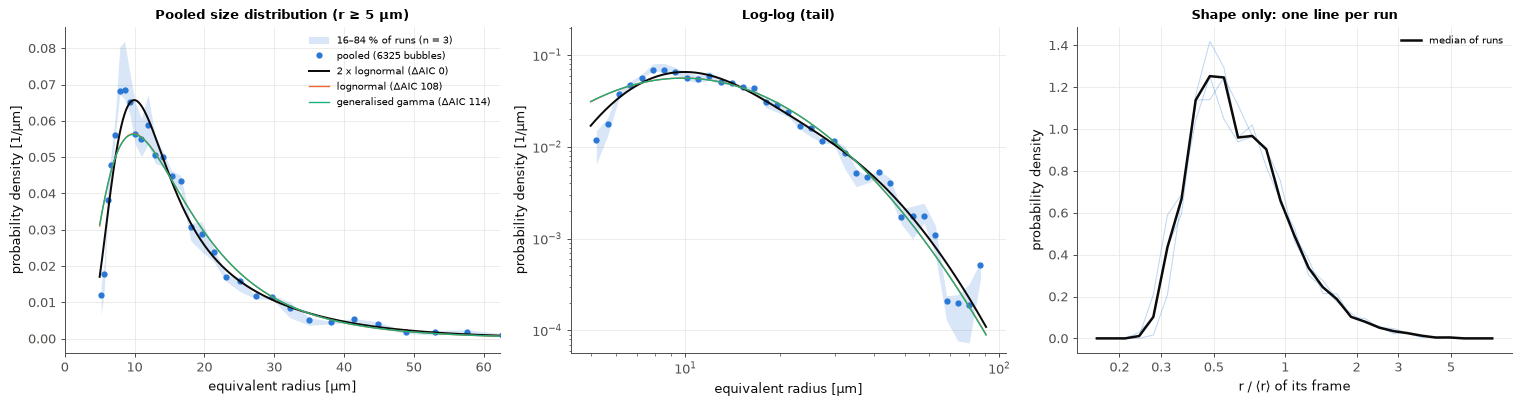

In [23]:
POOL_EXCLUDE = LAYERS if FIT_EXCLUDE_LAYERS else None
pb, px, pw = bc.pooled_sample(bubbles, m, rmin=FIT_RMIN_UM, exclude=POOL_EXCLUDE, weight=FIT_WEIGHT)
fit_tab, fits = bc.fit_pooled(px, pw, rmin=FIT_RMIN_UM)
fit_tab.to_csv(os.path.join(OUT_DIR, "pooled_fits.csv"), index=False)
with pd.option_context("display.max_colwidth", 120):
    display(fit_tab.round(3))
fig = bc.plot_pooled(pb, px, pw, fits, fit_tab, rmin=FIT_RMIN_UM)
save(fig, "pooled_distribution")

# the tail on its own: is the shape above the small-bubble peak still the same family?
tb, tx, tw = bc.pooled_sample(bubbles, m, rmin=FIT_TAIL_RMIN_UM, exclude=POOL_EXCLUDE, weight=FIT_WEIGHT)
tail_tab, _ = bc.fit_pooled(tx, tw, rmin=FIT_TAIL_RMIN_UM, models=["lognormal", "gamma", "Weibull", "generalised gamma"])
with pd.option_context("display.max_colwidth", 120):
    display(tail_tab.round(3))

F.clear("Pooled size distribution")
best = fit_tab.iloc[0]
F.add("Pooled size distribution", f"{len(px)} bubbles with r ≥ {FIT_RMIN_UM:g} µm from {pb['frame'].nunique()} frames "
      f"({pb['run'].nunique()} runs), weights per {FIT_WEIGHT}"
      + (", layer trains excluded" if POOL_EXCLUDE else "") + ". Fits ranked by AIC: " + "; ".join(
      f"{r.model} ΔAIC {r.dAIC:.0f}, KS D {r.KS_D:.3f}" for r in fit_tab.itertuples()))
F.add("Pooled size distribution", f"best: {best.model}: {best.params}; mode {best.mode_um:.1f} µm, mean "
      f"{best.mean_um:.1f} µm, skewness {best.skewness:.2f}")
ln = fit_tab[fit_tab["model"] == "lognormal"].iloc[0]
F.add("Pooled size distribution", f"lognormal: {ln.params}, mode {ln.mode_um:.1f} µm, skewness {ln.skewness:.2f}")
F.add("Pooled size distribution", f"tail only (r ≥ {FIT_TAIL_RMIN_UM:g} µm, {len(tx)} bubbles): " + "; ".join(
      f"{r.model} ΔAIC {r.dAIC:.0f}, KS D {r.KS_D:.3f} ({r.params})" for r in tail_tab.itertuples()))
if N_BOOT:
    bt = bc.bootstrap_runs(pb, rmin=FIT_RMIN_UM, model="lognormal", weight=FIT_WEIGHT, n_boot=N_BOOT)
    med, sig = np.exp(bt["theta1"]), np.exp(bt["theta0"])
    q = lambda v: f"{np.median(v):.2f} [{np.percentile(v, 16):.2f}, {np.percentile(v, 84):.2f}]"
    F.add("Pooled size distribution", f"lognormal over {N_BOOT} run resamples (median [16, 84 %]): median r {q(med)} µm, "
          f"σ(ln r) {q(sig)}, mode {q(bt['mode_um'])} µm, skewness {q(bt['skewness'])}")


## 10. Spatial organisation

* **Clark-Evans R** compares the mean nearest-neighbour distance with that of randomly placed points at the same
  density (edge-corrected): R < 1 clustered (e.g. bubbles along scan lines or a damaged region), R > 1 evenly spaced
  (bubbles keeping a distance, e.g. after neighbours merged).
* **Drift:** path of the area-weighted centroid from the first train. A shared direction across runs suggests a
  systematic cause (buoyancy, tissue flow or sample motion); random directions suggest local reorganisation.

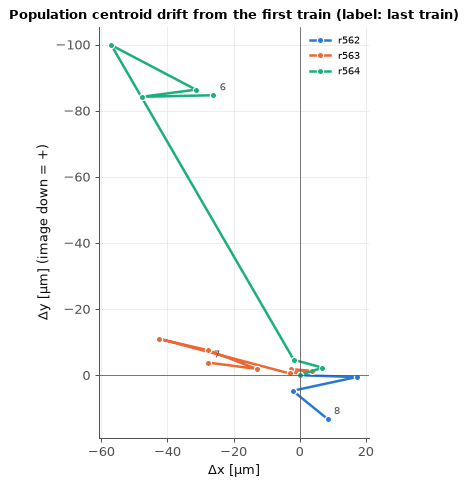

In [24]:
fig = bc.plot_drift_runs(m, NATIVE_HW, um_per_px=UM_PER_PX)
save(fig, "drift_runs")
F.clear("Spatial")
ce_all = m["clark_evans"].dropna()
if len(ce_all):
    t_, p_ = stats.wilcoxon(ce_all - 1) if len(ce_all) >= 6 else (np.nan, np.nan)
    F.add("Spatial", f"Clark-Evans R median {ce_all.median():.2f} (range {ce_all.min():.2f}–{ce_all.max():.2f}) → "
          + ("clustered" if ce_all.median() < 0.95 else "evenly spaced" if ce_all.median() > 1.05 else "close to random")
          + (f"; differs from 1: {bc.fmt_p(p_)}" if np.isfinite(p_) else ""))
net = []
for run, g in m.sort_values("t").groupby("run"):
    dx, dy = g["cx_um"].iloc[-1] - g["cx_um"].iloc[0], g["cy_um"].iloc[-1] - g["cy_um"].iloc[0]
    net.append((run, dx, dy))
ang = np.arctan2([d[2] for d in net], [d[1] for d in net])
R = np.hypot(np.cos(ang).mean(), np.sin(ang).mean())
F.add("Spatial", "net centroid drift first → last train: " + ", ".join(f"{r} ({dx:+.0f}, {dy:+.0f}) µm" for r, dx, dy in net)
      + f"; direction consistency across runs {R:.2f} (1 = all the same direction, ~0 = random)")

## 11. Shape

Freshly merged bubbles are elongated until surface tension (and the tissue) rounds them. If merging drives the
evolution, the share of non-circular bubbles should be higher after coalescence steps.

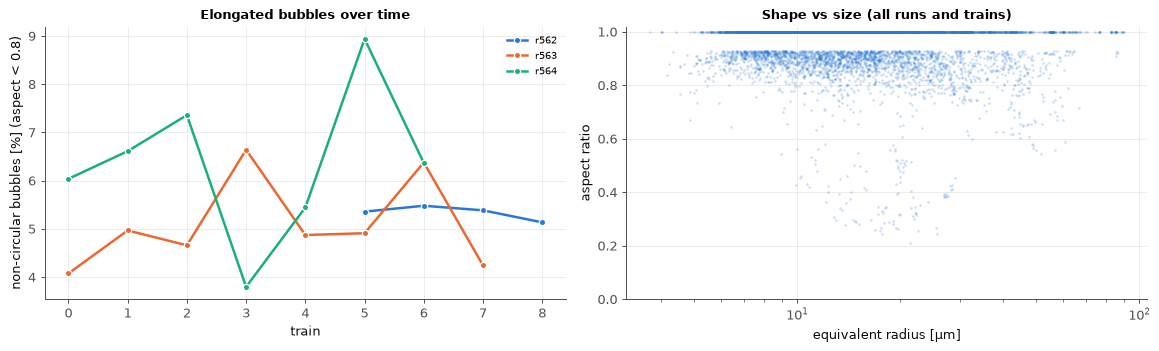

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for run, g in m.sort_values("t").groupby("run"):
    ax[0].plot(g["t"], g["frac_noncircular"] * 100, "-o", color=COLS[run], ms=5, mec="white", label=run)
ax[0].set_xlabel(TIME_LABEL); ax[0].set_ylabel("non-circular bubbles [%] (aspect < 0.8)"); ax[0].legend(fontsize=8)
ax[0].set_title("Elongated bubbles over time", fontsize=10)
asp = bubbles["minor_axis"] / bubbles["major_axis"].clip(lower=1e-9)
ax[1].scatter(bubbles["r_eq_um"], asp, s=4, color=bst.C[0], alpha=0.25, lw=0)
ax[1].set_xscale("log"); ax[1].set_ylim(0, 1.02)
ax[1].set_xlabel("equivalent radius [µm]"); ax[1].set_ylabel("aspect ratio")
ax[1].set_title("Shape vs size (all runs and trains)", fontsize=10)
fig.tight_layout(); save(fig, "shape")

F.clear("Shape")
rho, p = stats.spearmanr(bubbles["r_eq_um"], asp)
F.add("Shape", f"aspect ratio vs size: ρ = {rho:+.2f} ({bc.fmt_p(p)}) → "
      + ("large bubbles are less round" if rho < -0.1 else "small bubbles are less round" if rho > 0.1 else "no strong size dependence"))
mm = m.set_index(["run", "train"])["frac_noncircular"]
st["noncirc_after"] = [mm.get((r.run, r.train_to), np.nan) - mm.get((r.run, r.train_from), np.nan) for r in st.itertuples()]
g = st.groupby("kind")["noncirc_after"].mean()
F.add("Shape", "change of the non-circular share by step class: " + ", ".join(f"{k} {v * 100:+.1f} pts" for k, v in g.items()))
if len(st) >= 6:
    rho, p = stats.spearmanr(np.log(st["count_ratio"]), st["noncirc_after"])
    F.add("Shape", f"count change vs change of non-circular share across steps: ρ = {rho:+.2f} ({bc.fmt_p(p)})"
          + (" → fewer bubbles go with more elongated ones (merging)" if rho < 0 and p < ALPHA else ""))

## 12. Layer trains vs the rest

Compares the trains in `LAYERS` (known from `KNOWN_LAYER_TRAINS` plus the jumps detected in section 5) with all
other trains: each metric relative to the same run's median over its other trains, so differences between runs
cancel. Mann-Whitney test between the two groups.

In [26]:
F.clear("Layer trains")
if LAYERS:
    is_layer = np.array([(r, t) in LAYERS for r, t in zip(m["run"], m["train"])])
    rel = m.copy()
    for c in TREND_COLS:
        base = m[~is_layer].groupby("run")[c].median()
        rel[c] = m[c] / m["run"].map(base)
    rows = []
    for c in TREND_COLS:
        a, b = rel.loc[is_layer, c].dropna(), rel.loc[~is_layer, c].dropna()
        if len(a) and len(b) >= 2:
            u, p = stats.mannwhitneyu(a, b) if len(a) >= 2 else (np.nan, np.nan)
            rows.append(dict(metric=c, layer_rel=a.median(), other_rel=b.median(), p=p))
    lt = pd.DataFrame(rows).set_index("metric")
    display(lt.round(3))
    F.add("Layer trains", f"{len(LAYERS)} layer/jump trains: {sorted(LAYERS)}")
    for c, r in lt.iterrows():
        if abs(r.layer_rel - 1) > 0.1 or (np.isfinite(r.p) and r.p < ALPHA):
            F.add("Layer trains", f"{LABELS.get(c, c)}: ×{r.layer_rel:.2f} of the run's usual value"
                  + (f" ({bc.fmt_p(r.p)})" if np.isfinite(r.p) else " (one train, no test)"))
else:
    print("no layer trains known or detected")
    F.add("Layer trains", "none known (KNOWN_LAYER_TRAINS empty) and none detected as jumps")

,layer_rel,other_rel,p
metric,,,
n_bubbles,1.418,1.0,0.012
r_mean_um,0.832,1.0,0.012
r_median_um,0.785,1.0,0.012
r32_um,0.932,1.0,0.187
polydispersity,1.095,1.0,0.140
coverage_frac,1.037,1.0,0.292
volume_um3,0.978,1.0,0.842
frac_small,1.690,1.0,0.012
frac_noncircular,0.789,1.0,0.234


## 13. Overlays

The frames themselves, one figure per run, bubbles coloured by area on one shared logarithmic scale (green small,
red large). Needs the frame `.tif` copies in each run's `shapes/` folder.

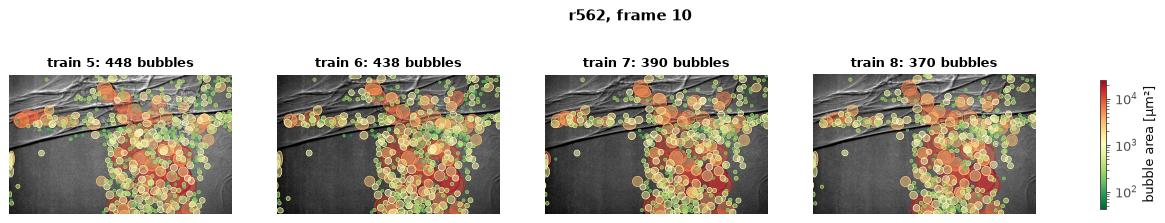

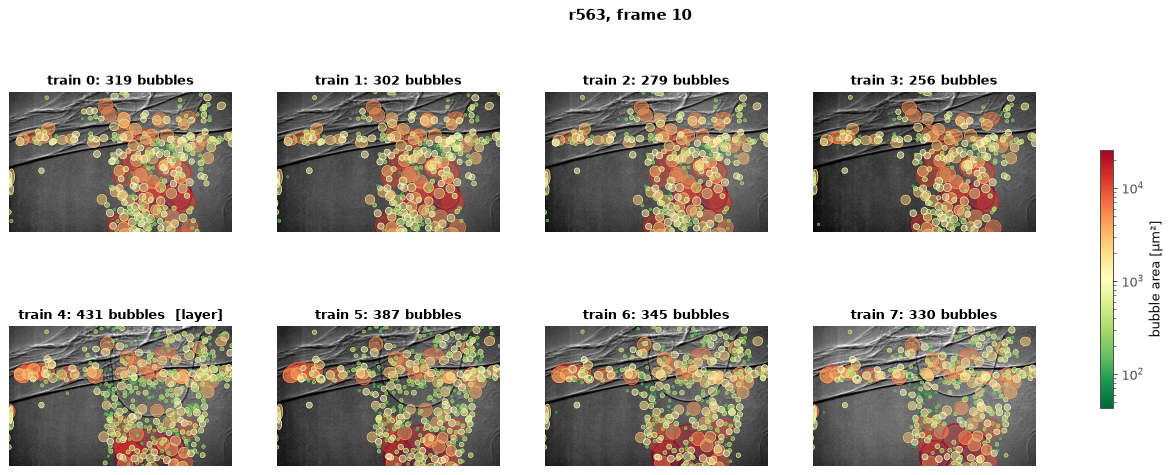

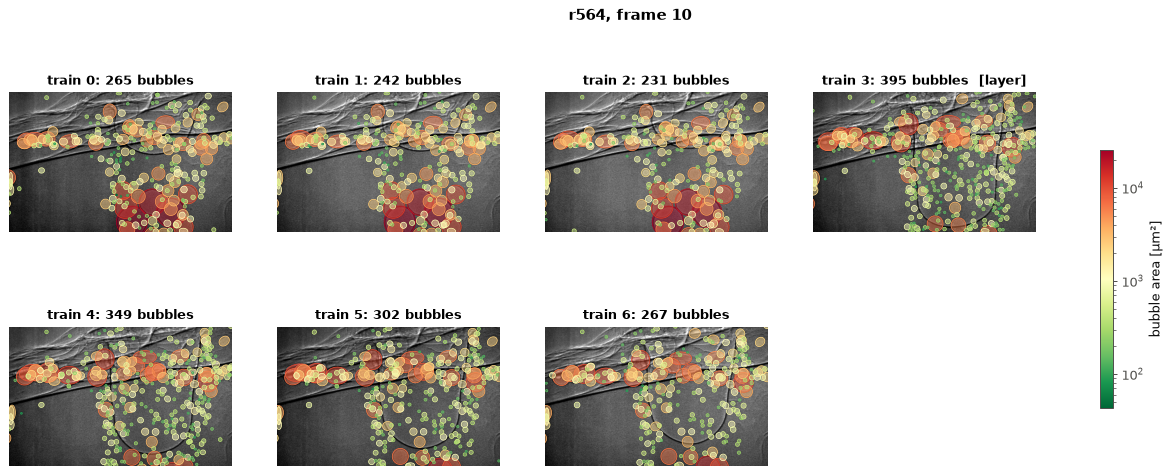

In [27]:
if SHOW_OVERLAYS:
    norm = bst.area_norm(bubbles, "area_um2")
    for run in RUNS_FOUND:
        g = m[m["run"] == run].sort_values("t")
        ncols = 4
        nrows = int(np.ceil(len(g) / ncols))
        fig, axs = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 3.1 * nrows), squeeze=False)
        for ax, r in zip(axs.ravel(), g.itertuples()):
            try:
                img, shapes = bio.load_frame(frames.loc[frames["frame"] == r.frame, "run_dir"].iloc[0], r.frame)
            except FileNotFoundError:
                ax.set_visible(False); continue
            b = bubbles[bubbles["frame"] == r.frame]
            hot = (run, r.train) in LAYERS
            bst.plot_area_overlay(img, [shapes[i] for i in b["bubble_id"]], b["area_um2"].to_numpy(), norm, ax=ax,
                                  title=f"train {r.train}: {len(b)} bubbles" + ("  [layer]" if hot else ""))
        for ax in axs.ravel()[len(g):]:
            ax.set_visible(False)
        fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="RdYlGn_r"), ax=axs.ravel().tolist(), shrink=0.6,
                     label="bubble area [µm²]")
        fig.suptitle(f"{run}, frame {FRAME_IDX}", fontweight="bold")
        save(fig, f"overlays_{run}")

## 14. Findings

Everything above in one text box. Copy it into the chat to discuss. It is also saved as `findings.txt` in
`OUT_DIR`. Numbers are computed from the data; the interpretations ("→ …") are rules of thumb to check against the
images.

In [28]:
head = (f"BUBBLE RUN x TRAIN COMPARISON, frame {FRAME_IDX} | runs {', '.join(RUNS_FOUND)} | "
        f"{'reviewed only' if REVIEWED_ONLY else 'model predictions incl. unreviewed'} | alpha = {ALPHA}")
txt = F.text(head)
with open(os.path.join(OUT_DIR, "findings.txt"), "w") as f:
    f.write(txt)
print(txt)

| BUBBLE RUN x TRAIN COMPARISON, frame 10 | runs r562, r563, r564 | model predictions incl. unreviewed | alpha = 0.05 |
|                                                                                                                     |
| [Data]                                                                                                              |
| - 3 runs (r562, r563, r564), frame 10 of trains [0, 1, 2, 3, 4, 5, 6, 7, 8]: 19 frames, 6346 bubbles; 0/19          |
|   frames reviewed in napari (the rest are raw model predictions). Field of view 1280 × 800 µm, time axis:           |
|   train.                                                                                                            |
| - left out 5 frames with < 30 bubbles (before the scan reached the field of view?), (run, train, n):                |
|   [('r562', 0, 16), ('r562', 1, 16), ('r562', 2, 12), ('r562', 3, 11), ('r562', 4, 26)]                             |
| - missing frames (run, train): [('r562

## Caveats

* One frame per train: the frame-to-frame scatter within a train is unknown, so "run × train + noise" in section 7
  mixes real differences in evolution with measurement noise. A few frames per train (e.g. 8–12) would separate
  them (`FRAME_IDX = None` loads every frame).
* Unreviewed model predictions carry the model's errors (missed faint bubbles, merged neighbours); compare a
  reviewed subset before trusting small effects.
* 2-D projections of a 3-D foam: overlapping bubbles are all counted, `packing` can exceed 1, the volume proxy
  assumes spheres.
* Many tests are run; with α = 0.05 about one in twenty is significant by chance. Trust effects that are large,
  consistent across runs and visible in the images.

## Your analysis